# 04 · Time Series and Walk-Forward Validation

A different dataset: `turbine_daily.csv`, two years of daily readings for forty
turbines. It has trend, weekly seasonality, a regime change, a telemetry gap, and
failures preceded by a rising run-up.

The task: predict whether a turbine will fail in the next 7 days.

You will build it wrong first — with a random split — see the excellent score,
then do it properly and watch the number fall to something honest.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

pd.set_option("display.width", 120); pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

ROOT = Path.cwd()
while not (ROOT / "data" / "turbine_readings.csv").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
CLEAN = ROOT / "data" / "turbine_clean.csv"
if not CLEAN.exists():
    raise SystemExit("Run Block 1 notebook 02 first — it produces turbine_clean.csv")
print("reading", CLEAN.name)

reading turbine_clean.csv


In [2]:
ts = pd.read_csv(ROOT / "data" / "turbine_daily.csv", parse_dates=["date"])
ts = ts.sort_values(["turbine_id", "date"]).reset_index(drop=True)
print(f"{len(ts):,} rows | {ts['turbine_id'].nunique()} turbines")
print(f"{ts['date'].min().date()} to {ts['date'].max().date()}")
ts.head()

29,116 rows | 40 turbines
2024-09-01 to 2026-08-31


,turbine_id,date,vibration_mm_s,gearbox_temp_c,power_output_kw,failure
0,T000,2024-09-01,0.1623,56.1,1845.4,0
1,T000,2024-09-02,0.2505,66.5,2234.9,0
2,T000,2024-09-03,0.2006,60.9,1708.4,0
3,T000,2024-09-04,0.2107,66.2,1777.1,0
4,T000,2024-09-05,0.2049,64.0,1573.2,0


## Always plot it first

Trend, seasonality, level shifts and gaps are visible in one chart and invisible
in `describe()`.

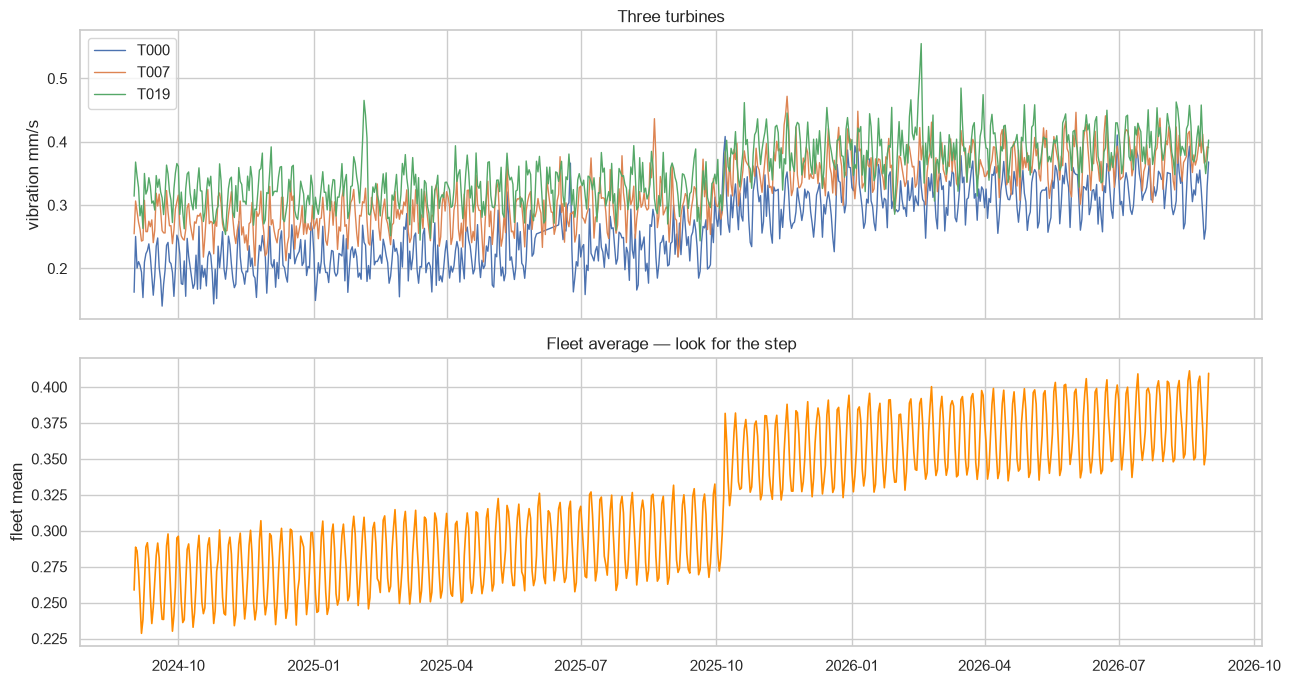

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for tid in ["T000", "T007", "T019"]:
    sub = ts[ts["turbine_id"] == tid]
    axes[0].plot(sub["date"], sub["vibration_mm_s"], lw=1, label=tid)
axes[0].set_ylabel("vibration mm/s"); axes[0].legend(); axes[0].set_title("Three turbines")

daily = ts.groupby("date")["vibration_mm_s"].mean()
axes[1].plot(daily.index, daily.values, lw=1.2, color="darkorange")
axes[1].set_ylabel("fleet mean"); axes[1].set_title("Fleet average — look for the step")
plt.tight_layout()

### Two things that chart shows

**A step change** partway through — a sensor recalibration. Data before and after
are not on the same scale, which is an argument for a sliding window rather than
an expanding one.

**A gap** where six turbines stopped reporting for a fortnight. Lag features
computed naively across that gap will silently compare readings two weeks apart
as though they were consecutive.

In [4]:
gaps = (ts.groupby("turbine_id")["date"].apply(lambda d: d.diff().dt.days.max()))
print("largest gap between consecutive readings, per turbine:")
print(gaps.value_counts().to_string())
print("\nTurbines with a gap longer than one day:", (gaps > 1).sum())

largest gap between consecutive readings, per turbine:


date
1.0     34
15.0     6

Turbines with a gap longer than one day: 6


## Build the target and the features

Target: does this turbine fail within the next 7 days?

Features must only ever look **backwards**. Every rolling window below is
computed within a turbine and shifted, so today's row never contains today's
value or any future one.

In [5]:
g = ts.groupby("turbine_id", group_keys=False)

# target: failure in the NEXT 7 days (looks forward — this is the label, not a feature)
ts["target"] = (g["failure"]
                .apply(lambda s: s.iloc[::-1].rolling(7, min_periods=1).max().iloc[::-1])
                .astype(int))

# features: backwards only. shift(1) so today's reading is excluded.
for col in ["vibration_mm_s", "gearbox_temp_c", "power_output_kw"]:
    prev = g[col].shift(1)
    ts[f"{col}_lag1"]   = prev
    ts[f"{col}_roll7"]  = prev.groupby(ts["turbine_id"]).rolling(7,  min_periods=3).mean().values
    ts[f"{col}_roll30"] = prev.groupby(ts["turbine_id"]).rolling(30, min_periods=7).mean().values
    ts[f"{col}_std7"]   = prev.groupby(ts["turbine_id"]).rolling(7,  min_periods=3).std().values

ts["vib_dev_from_norm"] = ts["vibration_mm_s_lag1"] - ts["vibration_mm_s_roll30"]
ts["dow"] = ts["date"].dt.dayofweek

FEATS = sorted({c for c in ts.columns if c.endswith(("_lag1","_roll7","_roll30","_std7"))} | {"vib_dev_from_norm", "dow"})
data = ts.dropna(subset=FEATS).reset_index(drop=True)
print(f"{len(data):,} usable rows, {len(FEATS)} features, target rate {data['target'].mean():.3%}")

28,836 usable rows, 14 features, target rate 1.897%


## The wrong way, so you can see the size of the lie

In [6]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score
from sklearn.model_selection import train_test_split

Xr, yr = data[FEATS], data["target"]
Xtr_r, Xte_r, ytr_r, yte_r = train_test_split(Xr, yr, test_size=0.25, random_state=0, stratify=yr)

m_random = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.06, max_iter=250,
                                          class_weight="balanced", random_state=0).fit(Xtr_r, ytr_r)
ap_random = average_precision_score(yte_r, m_random.predict_proba(Xte_r)[:, 1])
print(f"RANDOM split  → average precision {ap_random:.3f}")
print(f"(random-guessing baseline is {yr.mean():.3f})")

RANDOM split  → average precision 0.494
(random-guessing baseline is 0.019)


## The right way — split by time, with a gap

Two corrections. Train on the past and test on the future. And leave a **gap**
matching the horizon you are predicting: the target looks 7 days ahead, so
training rows within 7 days of the test period would share outcome information
with it.

In [7]:
cut = pd.Timestamp(data["date"].quantile(0.75))
gap_days = 7

GAP = np.timedelta64(gap_days, "D")   # pd.Timedelta(days=) warns under numpy 2.5
train = data[data["date"] <  cut - GAP]
test  = data[data["date"] >= cut]

print(f"train: {train['date'].min().date()} to {train['date'].max().date()}  ({len(train):,} rows)")
print(f"gap  : {gap_days} days")
print(f"test : {test['date'].min().date()} to {test['date'].max().date()}  ({len(test):,} rows)")

m_time = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.06, max_iter=250,
                                        class_weight="balanced", random_state=0
                                        ).fit(train[FEATS], train["target"])
ap_time = average_precision_score(test["target"], m_time.predict_proba(test[FEATS])[:, 1])

print(f"\nRANDOM split → {ap_random:.3f}")
print(f"TIME split   → {ap_time:.3f}")
print(f"\nThe random split was optimistic by {ap_random - ap_time:+.3f}.")
print("Nothing about the model changed. Only the question it was asked.")

train: 2024-09-08 to 2026-02-24  (21,316 rows)
gap  : 7 days
test : 2026-03-04 to 2026-08-31  (7,240 rows)



RANDOM split → 0.494
TIME split   → 0.343

The random split was optimistic by +0.151.
Nothing about the model changed. Only the question it was asked.


## Walk-forward validation

One time split is one estimate. Walk the boundary forward and you get several,
which tells you whether performance is stable or drifting.

In [8]:
from sklearn.model_selection import TimeSeriesSplit

dates = np.sort(data["date"].unique())
folds, rows = TimeSeriesSplit(n_splits=5), []

for i, (tr_idx, te_idx) in enumerate(folds.split(dates), 1):
    tr_end, te_start, te_end = dates[tr_idx[-1]], dates[te_idx[0]], dates[te_idx[-1]]
    tr = data[data["date"] <= pd.Timestamp(tr_end) - GAP]
    te = data[(data["date"] >= te_start) & (data["date"] <= te_end)]
    if te["target"].sum() < 3:
        continue
    mdl = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.06, max_iter=250,
                                         class_weight="balanced", random_state=0
                                         ).fit(tr[FEATS], tr["target"])
    rows.append({"fold": i,
                 "train_to": pd.Timestamp(tr_end).date(),
                 "test_from": pd.Timestamp(te_start).date(),
                 "n_test": len(te), "positives": int(te["target"].sum()),
                 "avg_precision": round(average_precision_score(
                     te["target"], mdl.predict_proba(te[FEATS])[:, 1]), 3)})
wf = pd.DataFrame(rows)
display(wf)
print(f"\nmean {wf['avg_precision'].mean():.3f}   sd {wf['avg_precision'].std():.3f}")

,fold,train_to,test_from,n_test,positives,avg_precision
0,1,2025-01-08,2025-01-09,4800,139,0.029
1,2,2025-05-08,2025-05-09,4716,142,0.441
2,3,2025-09-05,2025-09-06,4800,61,0.159
3,4,2026-01-03,2026-01-04,4800,156,0.400
4,5,2026-05-03,2026-05-04,4800,49,0.337



mean 0.273   sd 0.174


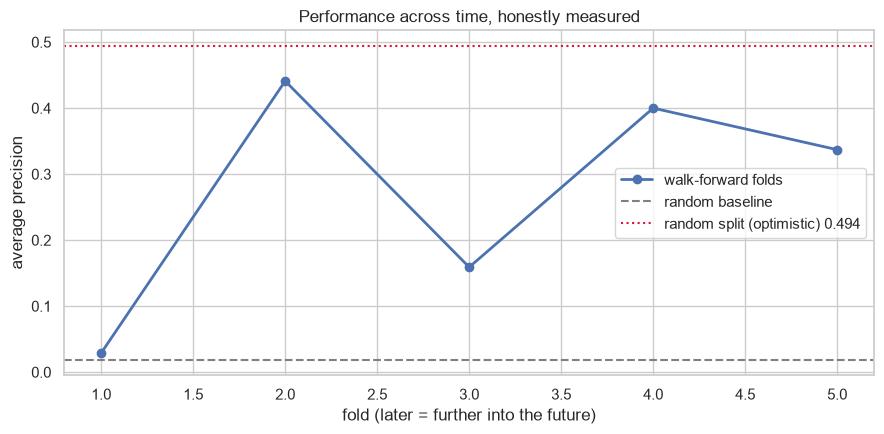

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(wf["fold"], wf["avg_precision"], marker="o", lw=2, label="walk-forward folds")
ax.axhline(data["target"].mean(), ls="--", color="grey", label="random baseline")
ax.axhline(ap_random, ls=":", color="crimson", label=f"random split (optimistic) {ap_random:.3f}")
ax.set_xlabel("fold (later = further into the future)"); ax.set_ylabel("average precision")
ax.set_title("Performance across time, honestly measured")
ax.legend(); plt.tight_layout()

### Reading the folds

If later folds are consistently worse, the process is drifting and you need to
retrain more often — or the regime change is hurting you and a sliding window
would beat an expanding one.

If they scatter without trend, that spread **is** your uncertainty. A single time
split would have given you one number from that spread and no way to know how
lucky it was.

## The naive baseline

The majority-class baseline of time series: predict that tomorrow looks like
today. Compute it before believing any model.

In [10]:
naive = test["vibration_mm_s_lag1"] > train["vibration_mm_s_lag1"].quantile(0.90)
ap_naive = average_precision_score(test["target"], naive.astype(float))

print(f"naive (yesterday's vibration in the top decile) : {ap_naive:.3f}")
print(f"model                                            : {ap_time:.3f}")
print(f"random guessing                                  : {test['target'].mean():.3f}")
print(f"\n{'The model beats the naive rule.' if ap_time > ap_naive else 'The model does NOT beat a one-line rule — that is the finding.'}")

naive (yesterday's vibration in the top decile) : 0.029
model                                            : 0.343
random guessing                                  : 0.017

The model beats the naive rule.


---

## What this notebook established

- Plot before modelling: the regime change and the telemetry gap are both visible
- Rolling features must be shifted and computed within each turbine
- A random split was optimistic, and by how much
- The gap between train and test must match the prediction horizon
- Walk-forward gives you a spread rather than one lucky number
- The naive rule, computed and compared

## Your turn

1. Remove the `shift(1)` from the rolling features and re-run the time split.
   The score jumps. Explain precisely which future information leaked in.
2. Use a sliding window (drop data before the regime change) instead of an
   expanding one. Do the later folds improve?
3. Change the horizon from 7 days to 30. Does the task get easier or harder, and
   does the required gap change?